In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# First let's import the packages
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import matplotlib
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)

pd.options.mode.chained_assignment = None
df=pd.read_csv('movies.csv')
df.head()



,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [ ]:
#check for missing data

for col in df.columns:
    percent_missing = np.mean(df[col].isnull())
    print('{} - {}%'.format(col, round(percent_missing*100)))

name - 0%
rating - 1%
genre - 0%
year - 0%
released - 0%
score - 0%
votes - 0%
director - 0%
writer - 0%
star - 0%
country - 0%
budget - 28%
gross - 2%
company - 0%
runtime - 0%


In [ ]:
df.isnull().sum()

,0
name,0
rating,77
genre,0
year,0
released,2
score,3
votes,3
director,0
writer,3
star,1


In [ ]:
df.dtypes


,0
name,object
rating,object
genre,object
year,int64
released,object
score,float64
votes,float64
director,object
writer,object
star,object


In [ ]:
df['budget'].round().astype('Int64')
df['budget']=df['budget'].astype('Int64')

df['gross'].round().astype('Int64')
df['gross']=df['gross'].astype('Int64')



changed budget and gross to int64;    needed whole number


In [ ]:
df['budget'].dtypes
df.dtypes

,0
name,object
rating,object
genre,object
year,int64
released,object
score,float64
votes,float64
director,object
writer,object
star,object


In [50]:
df['yearcorrect'] = df['released'].astype(str).str.split().str[2]

df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
5445,533,5,0,2009,696,7.8,1100000.0,1155,1778,2334,55,237000000,2847246203,2253,162.0,NaN
7445,535,5,0,2019,183,8.4,903000.0,162,743,2241,55,356000000,2797501328,1606,181.0,NaN
3045,6896,5,6,1997,704,7.8,1100000.0,1155,1778,1595,55,200000000,2201647264,2253,194.0,NaN
6663,5144,5,0,2015,698,7.8,876000.0,1125,2550,524,55,245000000,2069521700,1540,138.0,NaN
7244,536,5,0,2018,192,8.4,897000.0,162,743,2241,55,321000000,2048359754,1606,149.0,NaN


In [ ]:
df= df.sort_values(by=['gross'], inplace=False, ascending=False)

In [ ]:
pd.set_option('display.max_rows', None)

In [49]:
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
5445,533,5,0,2009,696,7.8,1100000.0,1155,1778,2334,55,237000000,2847246203,2253,162.0,2009.0
7445,535,5,0,2019,183,8.4,903000.0,162,743,2241,55,356000000,2797501328,1606,181.0,2019.0
3045,6896,5,6,1997,704,7.8,1100000.0,1155,1778,1595,55,200000000,2201647264,2253,194.0,1997.0
6663,5144,5,0,2015,698,7.8,876000.0,1125,2550,524,55,245000000,2069521700,1540,138.0,2015.0
7244,536,5,0,2018,192,8.4,897000.0,162,743,2241,55,321000000,2048359754,1606,149.0,2018.0


drop the duplicates

In [ ]:
df['company'].drop_duplicates().sort_values(ascending=False)

,company
7129,thefyzz
5664,micro_scope
6412,iDeal Partners Film Fund
4007,i5 Films
6793,i am OTHER
6420,erbp
3776,double A Films
524,Zupnik-Curtis Enterprises
3330,Zucker Brothers Productions
520,Zoetrope Studios


In [ ]:
import pandas as pd
import numpy as np

df['yearcorrect'] = pd.to_numeric(df['yearcorrect'], errors='coerce')

# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=[np.number])

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Display the correlation matrix
correlation_matrix

,year,score,votes,budget,gross,runtime,yearcorrect
year,1.000000,0.097995,0.222945,0.329321,0.257486,0.120811,0.997596
score,0.097995,1.000000,0.409182,0.076254,0.186258,0.399451,0.108188
votes,0.222945,0.409182,1.000000,0.442429,0.630757,0.309212,0.216092
budget,0.329321,0.076254,0.442429,1.000000,0.740395,0.320447,0.321048
gross,0.257486,0.186258,0.630757,0.740395,1.000000,0.245216,0.248977
runtime,0.120811,0.399451,0.309212,0.320447,0.245216,1.000000,0.120084
yearcorrect,0.997596,0.108188,0.216092,0.321048,0.248977,0.120084,1.000000


In [ ]:
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
5445,Avatar,PG-13,Action,2009,"December 18, 2009 (United States)",7.8,1100000.0,James Cameron,James Cameron,Sam Worthington,United States,237000000,2847246203,Twentieth Century Fox,162.0,2009.0
7445,Avengers: Endgame,PG-13,Action,2019,"April 26, 2019 (United States)",8.4,903000.0,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,356000000,2797501328,Marvel Studios,181.0,2019.0
3045,Titanic,PG-13,Drama,1997,"December 19, 1997 (United States)",7.8,1100000.0,James Cameron,James Cameron,Leonardo DiCaprio,United States,200000000,2201647264,Twentieth Century Fox,194.0,1997.0
6663,Star Wars: Episode VII - The Force Awakens,PG-13,Action,2015,"December 18, 2015 (United States)",7.8,876000.0,J.J. Abrams,Lawrence Kasdan,Daisy Ridley,United States,245000000,2069521700,Lucasfilm,138.0,2015.0
7244,Avengers: Infinity War,PG-13,Action,2018,"April 27, 2018 (United States)",8.4,897000.0,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,321000000,2048359754,Marvel Studios,149.0,2018.0


<Axes: xlabel='budget', ylabel='gross'>

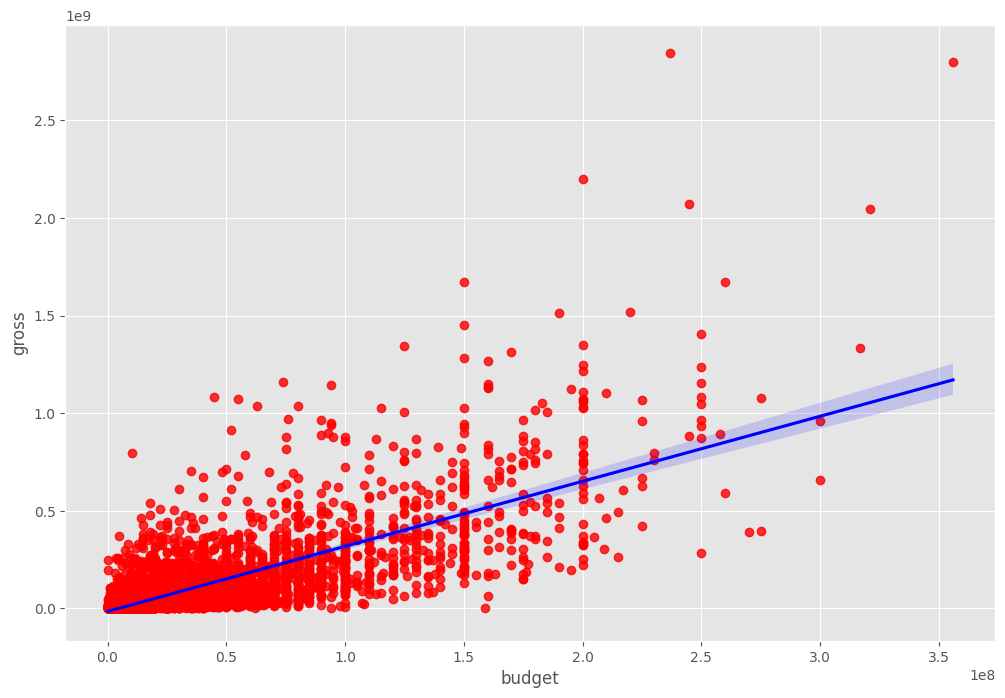

In [ ]:
#budget Vs gross udsing seaborn
sns.regplot(x="budget", y="gross", data=df, scatter_kws={"color": "red"}, line_kws={"color": "blue"})

Corelation matrix keeping it default at perason.

                 year     score     votes    budget     gross   runtime  \
year         1.000000  0.097995  0.222945  0.329321  0.257486  0.120811   
score        0.097995  1.000000  0.409182  0.076254  0.186258  0.399451   
votes        0.222945  0.409182  1.000000  0.442429  0.630757  0.309212   
budget       0.329321  0.076254  0.442429  1.000000  0.740395  0.320447   
gross        0.257486  0.186258  0.630757  0.740395  1.000000  0.245216   
runtime      0.120811  0.399451  0.309212  0.320447  0.245216  1.000000   
yearcorrect  0.997596  0.108188  0.216092  0.321048  0.248977  0.120084   

             yearcorrect  
year            0.997596  
score           0.108188  
votes           0.216092  
budget          0.321048  
gross           0.248977  
runtime         0.120084  
yearcorrect     1.000000  


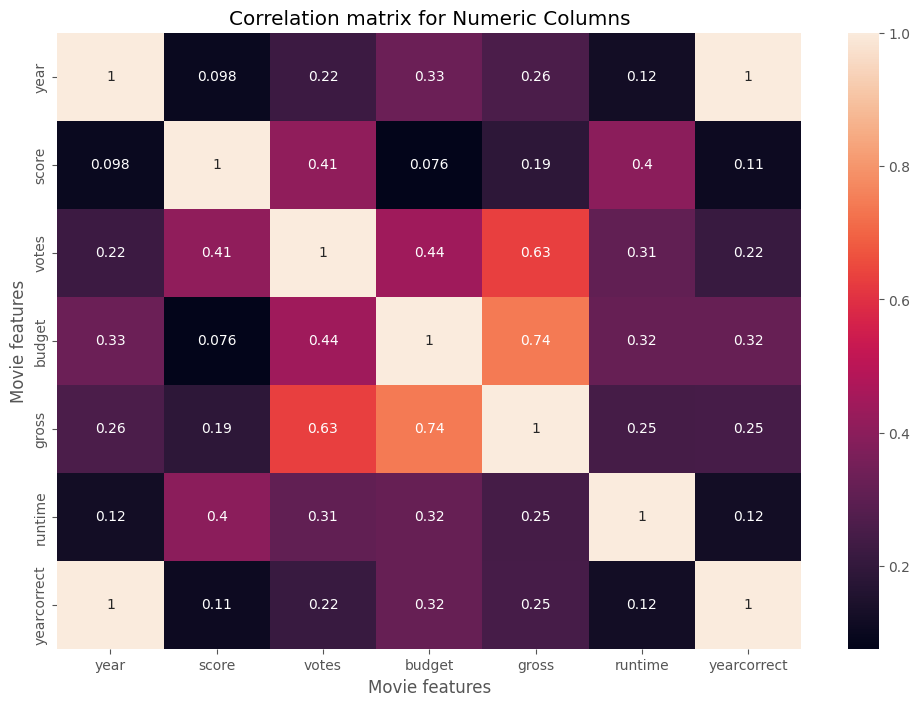

In [ ]:
# Correlation matrix across all numerical columns
correlation_matrix = df.corr(numeric_only=True,method='pearson')
print(correlation_matrix)
sns.heatmap(correlation_matrix, annot=True)
plt.title("Correlation matrix for Numeric Columns")
plt.xlabel("Movie features")
plt.ylabel("Movie features")
plt.show()


In [51]:
df_numerized = df
for col_name in df_numerized.columns:
    if(df_numerized[col_name].dtype == 'object'):
      df_numerized[col_name]= df_numerized[col_name].astype('category')
      df_numerized[col_name] = df_numerized[col_name].cat.codes
df_numerized.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
5445,533,5,0,2009,696,7.8,1100000.0,1155,1778,2334,55,237000000,2847246203,2253,162.0,NaN
7445,535,5,0,2019,183,8.4,903000.0,162,743,2241,55,356000000,2797501328,1606,181.0,NaN
3045,6896,5,6,1997,704,7.8,1100000.0,1155,1778,1595,55,200000000,2201647264,2253,194.0,NaN
6663,5144,5,0,2015,698,7.8,876000.0,1125,2550,524,55,245000000,2069521700,1540,138.0,NaN
7244,536,5,0,2018,192,8.4,897000.0,162,743,2241,55,321000000,2048359754,1606,149.0,NaN


In [52]:
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
5445,533,5,0,2009,696,7.8,1100000.0,1155,1778,2334,55,237000000,2847246203,2253,162.0,NaN
7445,535,5,0,2019,183,8.4,903000.0,162,743,2241,55,356000000,2797501328,1606,181.0,NaN
3045,6896,5,6,1997,704,7.8,1100000.0,1155,1778,1595,55,200000000,2201647264,2253,194.0,NaN
6663,5144,5,0,2015,698,7.8,876000.0,1125,2550,524,55,245000000,2069521700,1540,138.0,NaN
7244,536,5,0,2018,192,8.4,897000.0,162,743,2241,55,321000000,2048359754,1606,149.0,NaN


In [ ]:
df_numerized = df


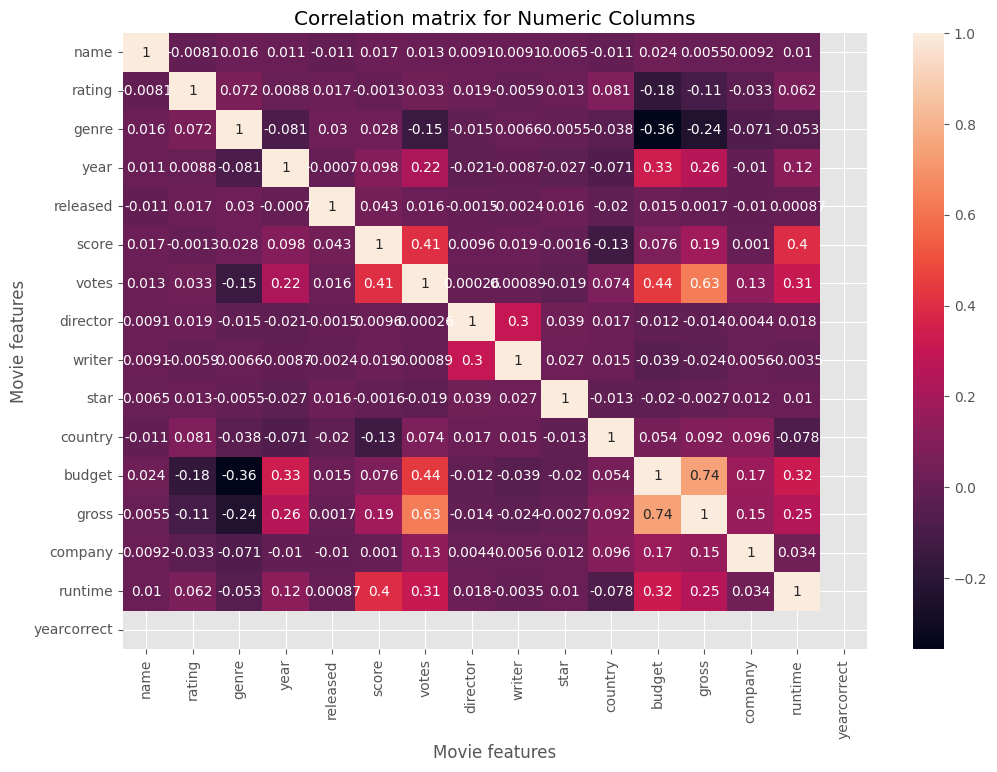

In [53]:
# Correlation matrix across all numerical columns
correlation_matrix_1 =df_numerized.corr(numeric_only=True,method='pearson')
sns.heatmap(correlation_matrix_1, annot=True)
plt.title("Correlation matrix for Numeric Columns")
plt.xlabel("Movie features")
plt.ylabel("Movie features")
plt.show()


In [ ]:
df_numerized.corr()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,yearcorrect
name,1.000000,-0.008069,0.016355,0.011453,-0.011311,0.017097,0.013088,0.009079,0.009081,0.006472,-0.010737,0.023970,0.005533,0.009211,0.010392,0.011431
rating,-0.008069,1.000000,0.072423,0.008779,0.016613,-0.001314,0.033225,0.019483,-0.005921,0.013405,0.081244,-0.176002,-0.107339,-0.032943,0.062145,0.007273
genre,0.016355,0.072423,1.000000,-0.081261,0.029822,0.027965,-0.145307,-0.015258,0.006567,-0.005477,-0.037615,-0.356564,-0.235650,-0.071067,-0.052711,-0.073969
year,0.011453,0.008779,-0.081261,1.000000,-0.000695,0.097995,0.222945,-0.020795,-0.008656,-0.027242,-0.070938,0.329321,0.257486,-0.010431,0.120811,0.997596
released,-0.011311,0.016613,0.029822,-0.000695,1.000000,0.042788,0.016097,-0.001478,-0.002404,0.015777,-0.020427,0.014683,0.001659,-0.010474,0.000868,-0.006376
score,0.017097,-0.001314,0.027965,0.097995,0.042788,1.000000,0.409182,0.009559,0.019416,-0.001609,-0.133348,0.076254,0.186258,0.001030,0.399451,0.108188
votes,0.013088,0.033225,-0.145307,0.222945,0.016097,0.409182,1.000000,0.000260,0.000892,-0.019282,0.073625,0.442429,0.630757,0.133204,0.309212,0.216092
director,0.009079,0.019483,-0.015258,-0.020795,-0.001478,0.009559,0.000260,1.000000,0.299067,0.039234,0.017490,-0.012272,-0.014441,0.004404,0.017624,-0.021035
writer,0.009081,-0.005921,0.006567,-0.008656,-0.002404,0.019416,0.000892,0.299067,1.000000,0.027245,0.015343,-0.039451,-0.023519,0.005646,-0.003511,-0.008312
star,0.006472,0.013405,-0.005477,-0.027242,0.015777,-0.001609,-0.019282,0.039234,0.027245,1.000000,-0.012998,-0.019589,-0.002717,0.012442,0.010174,-0.028796


In [ ]:
correlation_mat = df_numerized.corr()
corr_pairs = correlation_mat.unstack()
corr_pairs

name         name           1.000000
             rating        -0.008069
             genre          0.016355
             year           0.011453
             released      -0.011311
             score          0.017097
             votes          0.013088
             director       0.009079
             writer         0.009081
             star           0.006472
             country       -0.010737
             budget         0.023970
             gross          0.005533
             company        0.009211
             runtime        0.010392
             yearcorrect    0.011431
rating       name          -0.008069
             rating         1.000000
             genre          0.072423
             year           0.008779
             released       0.016613
             score         -0.001314
             votes          0.033225
             director       0.019483
             writer        -0.005921
             star           0.013405
             country        0.081244
             budget        -0.176002
             gross         -0.107339
             company       -0.032943
             runtime        0.062145
             yearcorrect    0.007273
genre        name           0.016355
             rating         0.072423
             genre          1.000000
             year          -0.081261
             released       0.029822
             score          0.027965
             votes         -0.145307
             director      -0.015258
             writer         0.006567
             star          -0.005477
             country       -0.037615
             budget        -0.356564
             gross         -0.235650
             company       -0.071067
             runtime       -0.052711
             yearcorrect   -0.073969
year         name           0.011453
             rating         0.008779
             genre         -0.081261
             year           1.000000
             released      -0.000695
             score          0.097995
             votes          0.222945
             director      -0.020795
             writer        -0.008656
             star          -0.027242
             country       -0.070938
             budget         0.329321
             gross          0.257486
             company       -0.010431
             runtime        0.120811
             yearcorrect    0.997596
released     name          -0.011311
             rating         0.016613
             genre          0.029822
             year          -0.000695
             released       1.000000
             score          0.042788
             votes          0.016097
             director      -0.001478
             writer        -0.002404
             star           0.015777
             country       -0.020427
             budget         0.014683
             gross          0.001659
             company       -0.010474
             runtime        0.000868
             yearcorrect   -0.006376
score        name           0.017097
             rating        -0.001314
             genre          0.027965
             year           0.097995
             released       0.042788
             score          1.000000
             votes          0.409182
             director       0.009559
             writer         0.019416
             star          -0.001609
             country       -0.133348
             budget         0.076254
             gross          0.186258
             company        0.001030
             runtime        0.399451
             yearcorrect    0.108188
votes        name           0.013088
             rating         0.033225
             genre         -0.145307
             year           0.222945
             released       0.016097
             score          0.409182
             votes          1.000000
             director       0.000260
             writer         0.000892
             star          -0.019282
             country        0.073625
             budget         0.442429
    

In [ ]:
sorted_pairs=corr_pairs.sort_values()
sorted_pairs

,,0
genre,budget,-0.356564
budget,genre,-0.356564
gross,genre,-0.235650
genre,gross,-0.235650
rating,budget,-0.176002
budget,rating,-0.176002
votes,genre,-0.145307
genre,votes,-0.145307
country,score,-0.133348
score,country,-0.133348


gross and bugget showed highest corelation!

votes and budget ahd highest corelation!

In [ ]:
high_corr= sorted_pairs[(sorted_pairs)>0.5]
high_corr

,,0
gross,votes,0.630757
votes,gross,0.630757
gross,budget,0.740395
budget,gross,0.740395
year,yearcorrect,0.997596
yearcorrect,year,0.997596
director,director,1.000000
votes,votes,1.000000
released,released,1.000000
score,score,1.000000
